# importing the data:

In [1]:
# Paths come from a .env file (see .env.example); defaults work if you run from this folder.
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True))
DATA_DIR   = Path(os.getenv("DATA_DIR", "."))          # folder holding train.csv / test.csv
PLOTS_DIR  = Path(os.getenv("PLOTS_DIR", "tmp"))        # EDA plots are saved here
MODELS_DIR = Path(os.getenv("MODELS_DIR", "tmp_models"))  # saved model pickles


In [2]:
#imports
import pandas as pd
from pprint import pprint

data = pd.read_csv(DATA_DIR / 'train.csv')
pprint(data.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


## seperating the surving feature for analysis:

In [3]:
survived_data = data[['Survived','PassengerId']]
feature_data = data.drop('Survived', axis=1)
num_cols = ['Age', 'SibSp', 'Parch', 'Fare']
cat_cols = ['Pclass','Sex','Cabin','Embarked']
df =data.copy()

## doing pre modeling analysis on the data:

In [4]:
#checking the data stats:
df[num_cols].describe()

,Age,SibSp,Parch,Fare
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208
std,14.526497,1.102743,0.806057,49.693429
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400
50%,28.000000,0.000000,0.000000,14.454200
75%,38.000000,1.000000,0.000000,31.000000
max,80.000000,8.000000,6.000000,512.329200


In [5]:
# checking missing values:
df[num_cols+cat_cols].isnull().sum()

Age         177
SibSp         0
Parch         0
Fare          0
Pclass        0
Sex           0
Cabin       687
Embarked      2
dtype: int64

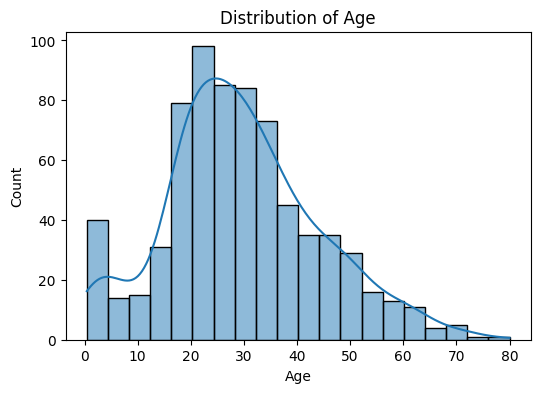

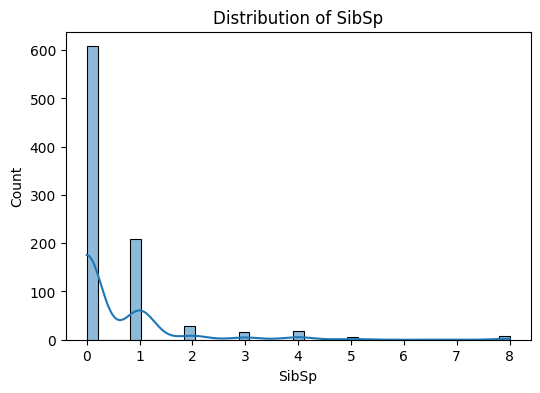

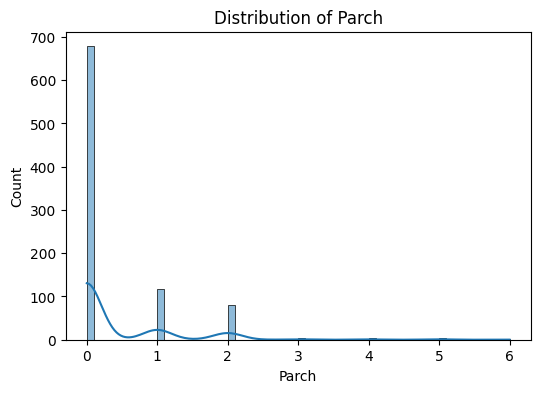

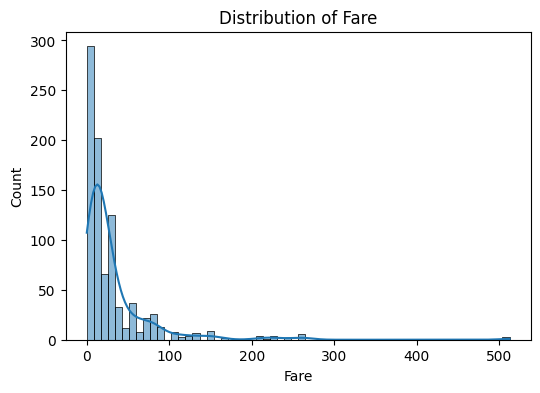

In [6]:
#numerical feature data distribution:
import matplotlib.pyplot as plt
import seaborn as sns

for cols in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[cols],kde=True)
    plt.title(f"Distribution of {cols}")
    plt.show()

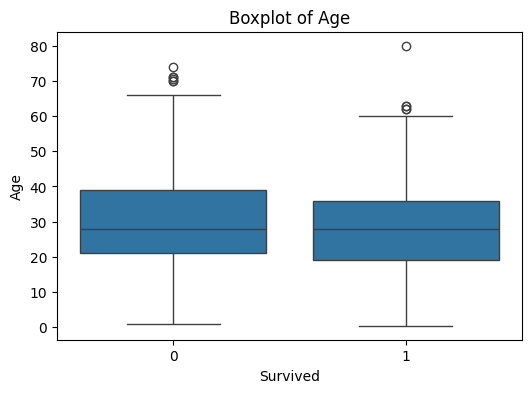

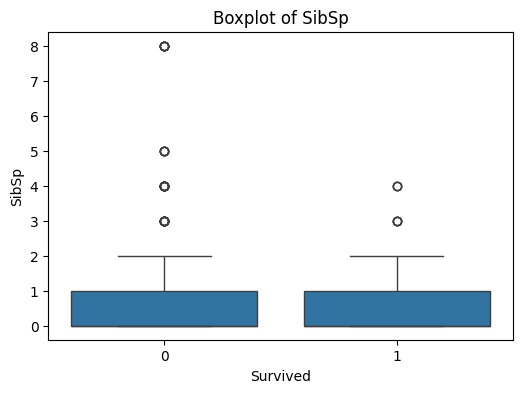

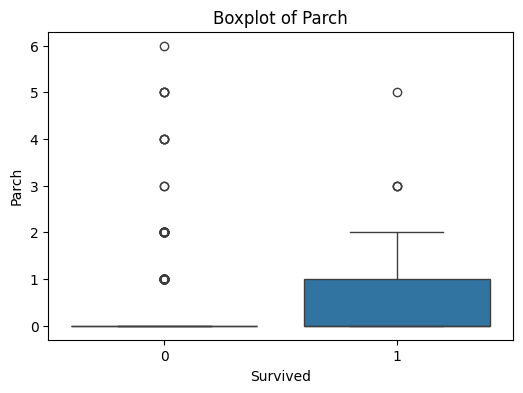

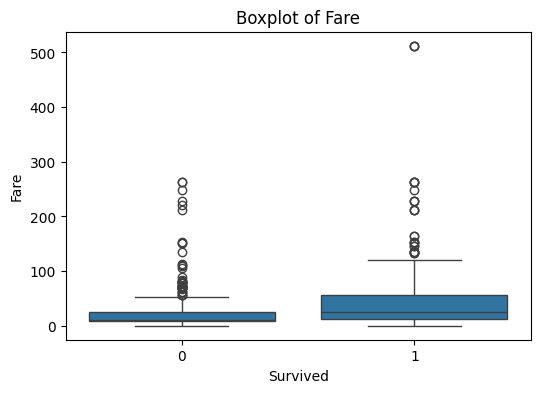

In [7]:
# checking outliers: using boxplot with the output feature
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x='Survived', y=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

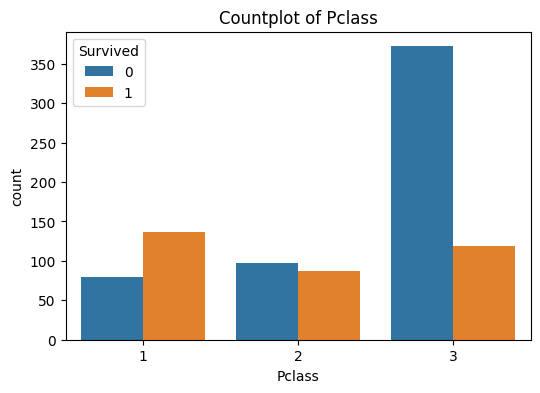

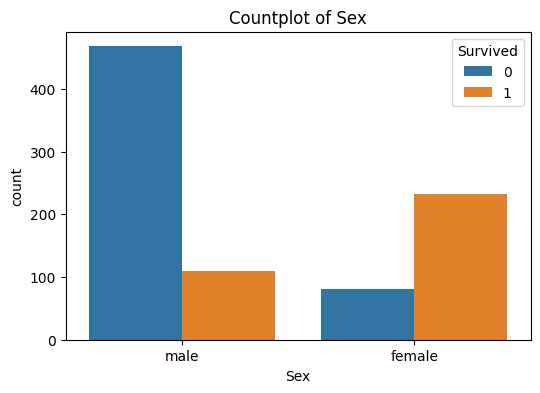

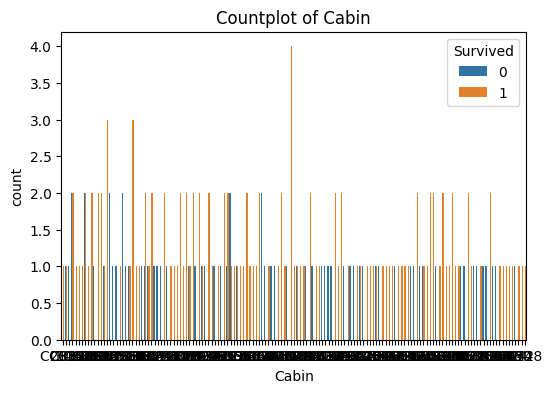

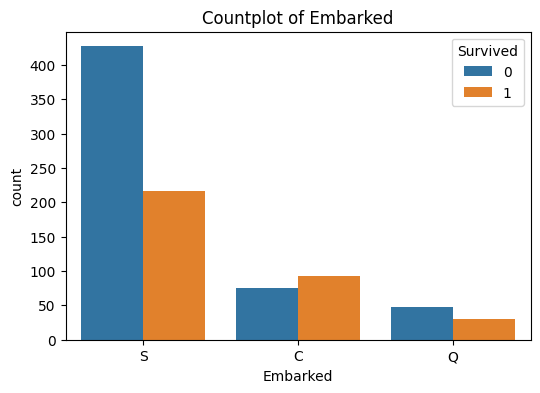

In [8]:
#categorical feature distribution:
for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col, hue='Survived')
    plt.title(f"Countplot of {col}")
    plt.show()

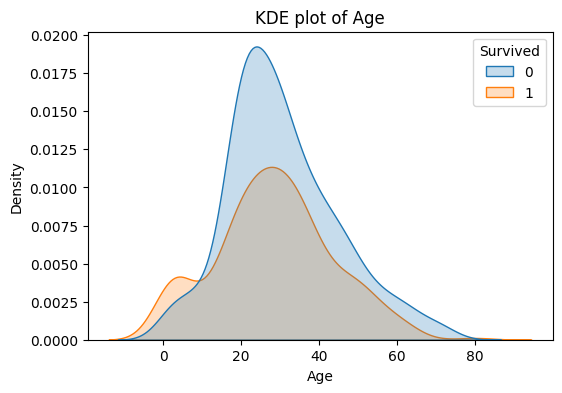

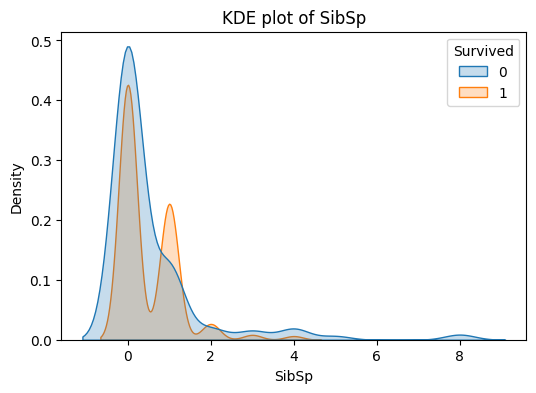

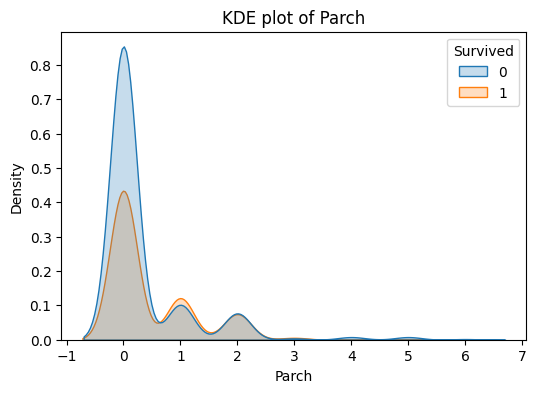

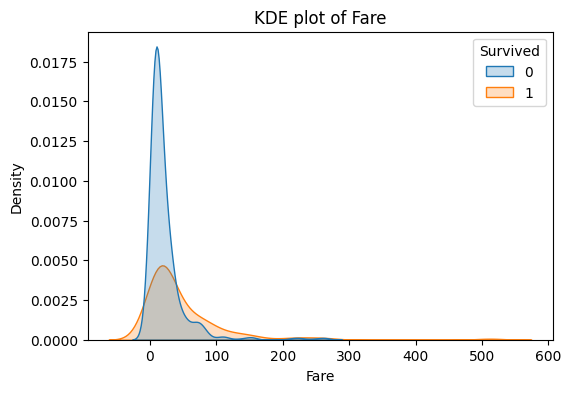

In [9]:
# numerical features vs survival:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue='Survived', fill=True)
    plt.title(f"KDE plot of {col}")
    plt.show()